# Example 9: Singularity

Let's construct a dataset which contains singularity $f(x,y)=sin(log(x)+log(y))
 (x>0,y>0)$

In [1]:
import copy

import torch
from xkan import KANNetwork, create_dataset, fit
from xkan.symbolic import fix_symbolic, symbolic_formula
from xkan.utils import ex_round
from xkan.viz import plot

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

# create a KAN: 2D inputs, 1D output, and 5 hidden neurons. cubic spline (k=3), 5 grid intervals (grid=5).
model = KANNetwork([2, 1, 1], grid=5, k=3, seed=2, device=device)
f = lambda x: torch.sin(2*(torch.log(x[:,[0]])+torch.log(x[:,[1]])))
train, test = create_dataset(f, n_var=2, ranges=[0.2,5], device=device)

# train the model
history = fit(model, train, test, steps=20)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)

cuda


train RMSE 0.12383098388404153 test RMSE 0.15637721604897045


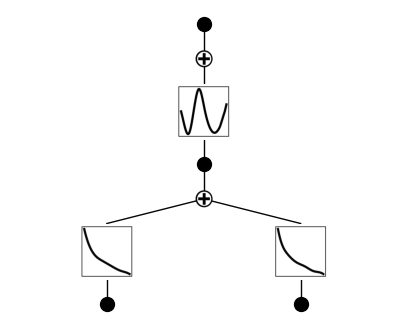

In [2]:
plot(model, train['x']);

In [3]:
# a_range_relative=False: a searched in [-10, 10]; the default divides that range by the largest |x| (5 here), and the
# smaller a it finds puts the arguments of the logs so close to 0 that the refit below goes to nan
print('r2 is', float(fix_symbolic(model, 0, 0, 0, 'log', train['x'], a_range_relative=False)))
print('r2 is', float(fix_symbolic(model, 0, 1, 0, 'log', train['x'], a_range_relative=False)))
print('r2 is', float(fix_symbolic(model, 1, 0, 0, 'sin', train['x'], a_range_relative=False)))

r2 is 0.9982253313064575
r2 is 0.9990173578262329
r2 is 0.977551281452179


In [4]:
# the arguments of the logs come close to 0: the singularity guard (singularity_avoiding, below) keeps the line search
# of LBFGS from stepping past it into nan
history = fit(model, train, test, steps=20, forward_kwargs=dict(singularity_avoiding=True))
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)

train RMSE 3.0318710561237076e-07 test RMSE 3.0559535311392293e-07


In [5]:
ex_round(symbolic_formula(model)[0][0], 3)

-1.0*sin(2.0*log(7.964*x_1) + 2.0*log(9.849*x_2) - 5.583)

The guard keeps the singularity of log harmless here; without it the refit can step into NaN, since the arguments of the logs come close to 0. Consider $f(x,y)=\sqrt{x^2+y^2}$ instead, which has a singular point at $x=y=0$.

In [6]:
import torch
from xkan import KANNetwork, create_dataset, fit

# create a KAN: 2D inputs, 1D output, and 5 hidden neurons. cubic spline (k=3), 5 grid intervals (grid=5).
# scale_sp_fan_in=False: each curve starts at full strength, as in pykan up to 0.2.7 (0.2.8 divides it by the square
# root of the layer's number of inputs, and this network then trains far worse)
model = KANNetwork([2, 1, 1], grid=5, k=3, seed=0, scale_sp_fan_in=False)
f = lambda x: torch.sqrt(x[:,[0]]**2+x[:,[1]]**2)
train, test = create_dataset(f, n_var=2)

# train the model
history = fit(model, train, test, steps=20)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)

train RMSE 0.0038451683660377656 test RMSE 0.004084164123046357


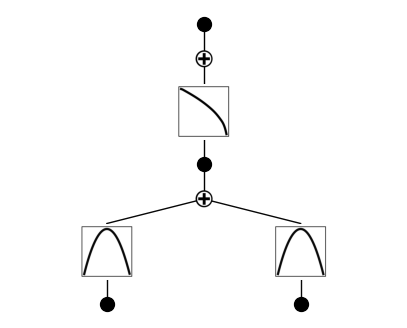

In [7]:
plot(model, train['x']);

In [8]:
print('r2 is', float(fix_symbolic(model, 0, 0, 0, 'x^2', train['x'])))
print('r2 is', float(fix_symbolic(model, 0, 1, 0, 'x^2', train['x'])))
print('r2 is', float(fix_symbolic(model, 1, 0, 0, 'sqrt', train['x'])))

# a network keeps no history of its states: keep a copy of this one to come back to
model_fixed = copy.deepcopy(model)

r2 is 0.9999902844429016
r2 is 0.9999973177909851
r2 is 0.9998964071273804


In [9]:
# back to the state after the three fixes
model = copy.deepcopy(model_fixed)

In [10]:
formula = symbolic_formula(model)[0][0]
formula

0.546630859375*sqrt(0.0429004016864274*(0.00168000184930861 - 8.87700843811035*x_2)**2 + 0.0434851748984248*(8.81580543518066*x_1 - 0.000960001139901578)**2 + 0.0101978874270889) - 0.00630775326862931

In [11]:
ex_round(formula, 2)

0.55*sqrt(3.1117728948334*x_1**2 + 3.15512932736482*x_2**2 + 0.01) - 0.01

w/ singularity avoiding (LBFGS may still get nan because of line search, but Adam won't get nan).

In [12]:
history = fit(model, train, test, steps=1000, opt="adam", lr=1e-3, update_grid=False,
              forward_kwargs=dict(singularity_avoiding=True))
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)

train RMSE 0.00015050880963122964 test RMSE 0.0001782289911402815


w/o singularity avoiding, nan may appear

In [13]:
history = fit(model, train, test, steps=1000, opt="adam", lr=1e-3, update_grid=False)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)

train RMSE nan test RMSE nan
